# Build FFT Bank corresponding to `Soundbank_McGill`

Followed notebook 1.4


# Reconstructing the FFT from a sound

Following [file://../Reading/MIT_J_Comp+Music-Rose-Hetrick.pdf](file://../Reading/MIT_J_Comp+Music-Rose-Hetrick.pdf)
    
<img src="../Imgs/fft_process.png" align='left'>


## Input sound: $~$ flu-e4-ord-mf.wav

In [177]:
from scipy.io import wavfile

In [178]:
insound = '../../STO/WWBr-IsolatedSounds/Flu_aif/flu-e4-ord-mf.wav'

rate, sounddata = wavfile.read(insound)
sounddata

array([0, 0, 0, ..., 0, 0, 0], dtype=int16)

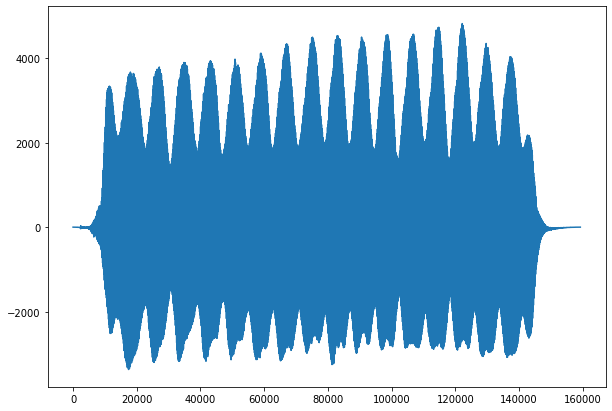

In [179]:
%matplotlib inline

# This function is in my startup file: \Users\jhetrick\.ipython\profile_default\startup\mystartupcmds.py
def setPLTdisplay(n, m):
    plt.rcParams['figure.figsize'] = (n, m)

setPLTdisplay(10,7)

plt.plot(range(len(sounddata)), sounddata)

In [182]:
#!pip install pydub

In [183]:
from pydub import AudioSegment
from pydub.playback import play

In [184]:
pwd

'C:\\Users\\jhetrick\\Dropbox\\Research\\Music\\OrchestrationEngine\\Notebooks'

In [185]:
#sound = AudioSegment.from_file('../../STO//flu-e4-ord-mf.wav')
#sound = AudioSegment.from_file('../../STO/WWBr-IsolatedSounds/Flu_aif/flu-e4-ord-mf', 'aiff')
sound = AudioSegment.from_file(insound)

#WWBr-IsolatedSounds/Flu_aif
sound

In [6]:
len(sound.get_array_of_samples())

159232

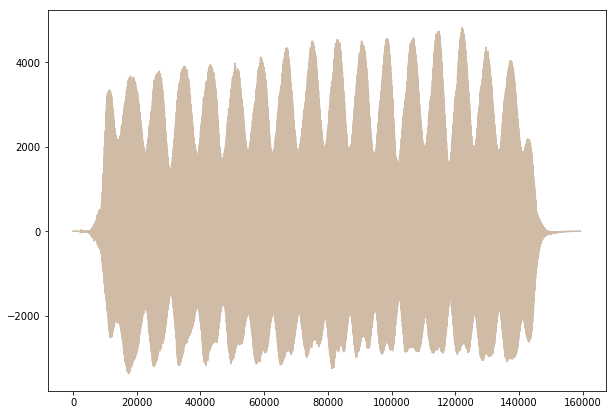

In [7]:
plt.plot(range(len(sounddata)), sounddata, alpha=0.3)
plt.plot(range(len(sound.get_array_of_samples())), sound.get_array_of_samples(), alpha=0.3)

So, the data read by *scipy.io.wave.read()*, and the data gotten from the *pydub* (using sound = AudioSegment; sound.get_array_of_samples())

$$-\infty-$$

## FFT

In [186]:
from scipy.fftpack import fft, ifft

For this file, the start and stop indicies are


e4 | 26535 | 129800

In [187]:
begin, end = 26535, 129800

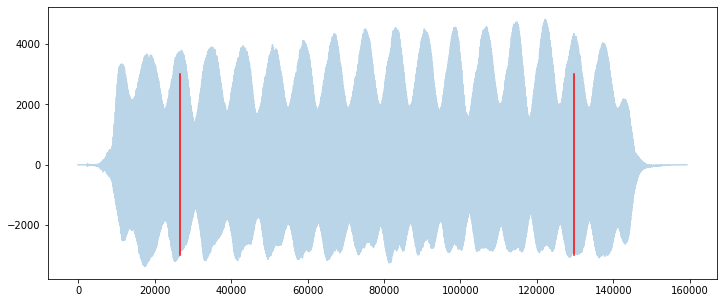

In [188]:
%matplotlib inline
setPLTdisplay(12,5)

plt.plot(range(len(sounddata)), sounddata, alpha=0.3)
plt.plot([begin,begin], [-3000,3000],'r')
plt.plot([end,end], [-3000,3000],'r')
plt.show()

---

In [189]:
hamwin = np.hamming(4096)

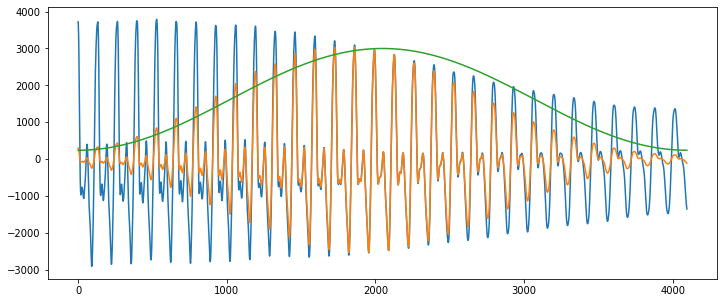

In [190]:
x = sounddata[begin:begin+4096]

plt.plot(range(4096), x)
plt.plot(range(4096), x*hamwin)
plt.plot(range(4096), 3000*hamwin)

In [191]:
n = 0
xf_ave = np.zeros(2048)

for i in range(begin, end-4096, 512):
    x = sounddata[i:i+4096]
    x = x * hamwin
    xf = fft(x)
    xf_ave += (np.absolute(xf)**2)[:2048]
    
    n+=1
    
xf_ave = np.sqrt(xf_ave)/n
xf_ave

array([8715.003, 3724.098,  256.203, ...,    7.435,    7.58 ,    7.395])

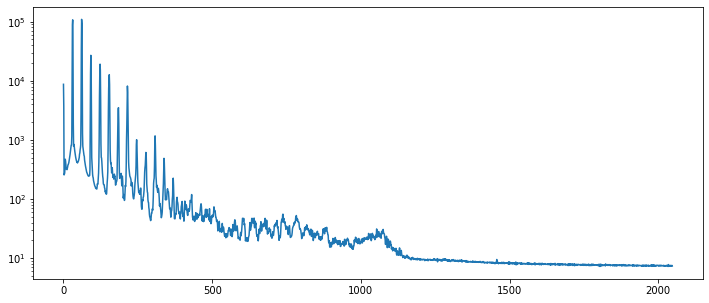

In [192]:
plt.plot(range(2048), xf_ave[:2048])
plt.yscale('log')

## Previous FFT:  $~$ flu-e4-ord-mf.nbb

In [193]:
srcfile = '../../FFTBank/flu-e4-ord-mf.nbb'
nbbfft = np.fromfile(srcfile, dtype='float32')

FileNotFoundError: [Errno 2] No such file or directory: '../../FFTBank/flu-e4-ord-mf.nbb'

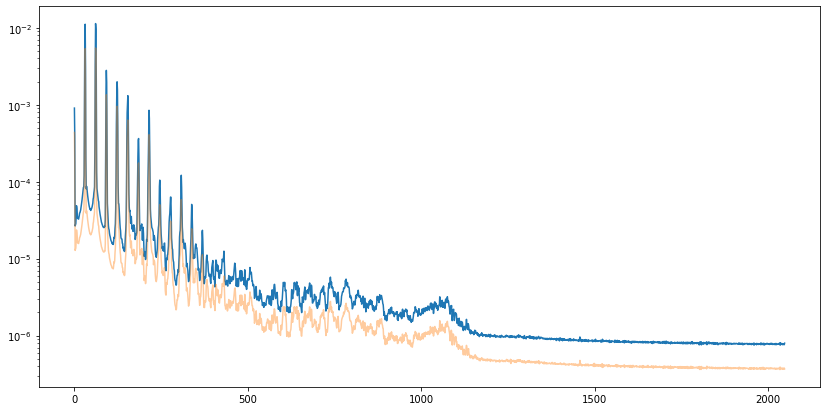

In [194]:
setPLTdisplay(14,7)

plt.plot(range(2048), nbbfft)
plt.plot(range(2048), xf_ave[:2048]/2e7, alpha=0.4)
plt.yscale('log')
#plt.xlim(0,500)

(0, 500)

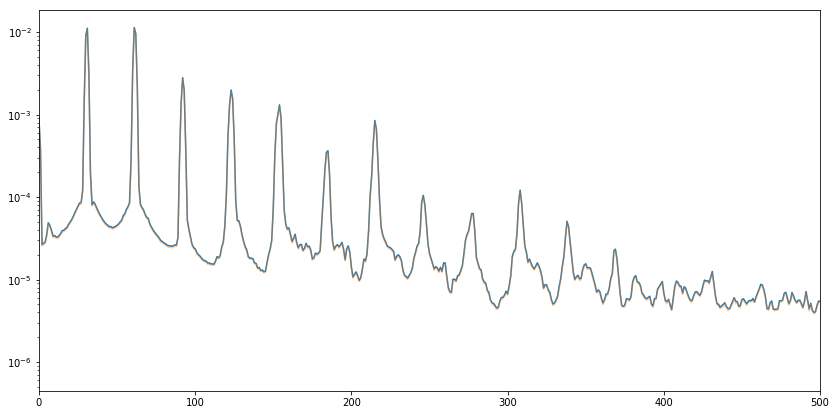

In [17]:
plt.plot(range(2048), nbbfft)
plt.plot(range(2048), xf_ave[:2048]/1e7, alpha=0.4)
plt.yscale('log')
plt.xlim(0,500)

the normalization coefficient is $\sim$ 1.e7

In [18]:
xf_ave[0]/nbbfft[0]

9634749.9542828035

---

$$-\infty-$$

---

Another sound

In [19]:
instrument = 'cla-e5-ord-mf'
folder = 'Cla_aif'

sound = AudioSegment.from_file('../WWBr-IsolatedSounds/' + folder +'/'+ instrument, 'aiff')
sounddata = sound.get_array_of_samples()

In [21]:
# e5	17070	163055
begin,end = 17070,163055

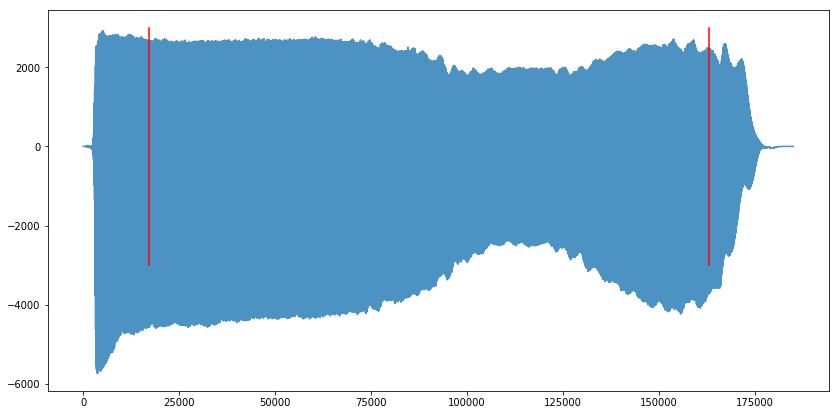

In [22]:
plt.plot(range(len(sounddata)), sounddata, alpha=0.8)
plt.plot([begin,begin], [-3000,3000],'r')
plt.plot([end,end], [-3000,3000],'r')

In [23]:
n = 0
xf_ave = np.zeros(2048)

for i in range(begin, end-4096, 512):
    x = sounddata[i:i+4096]
    x = x * hamwin
    xf = fft(x)
    xf_ave += (np.absolute(xf)**2)[0:2048]
    n+=1
    
xf_ave = np.sqrt(xf_ave)/n
xf_ave

array([ 8547.828,  5333.436,  2013.195, ...,     5.842,     5.755,
           5.677])

In [24]:
srcfile = '../Banknbb/' + instrument + '.nbb'
nbbfft = np.fromfile(srcfile, dtype='float32')

In [25]:
norm = xf_ave[0]/nbbfft[0]
norm

8108746.2950571273

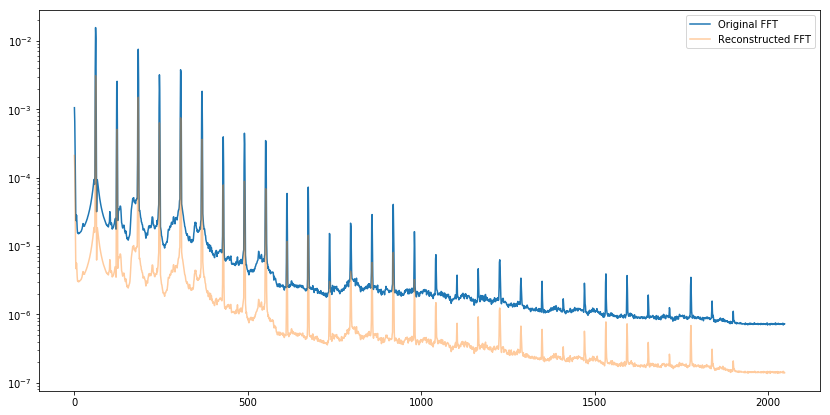

In [27]:
plt.plot(range(2048), nbbfft, label="Original FFT")
plt.plot(range(2048), xf_ave[:2048]/norm/5, alpha=0.4, label="Reconstructed FFT")
plt.yscale('log')
#plt.xlim(0,500)
plt.legend()

## Exact $~$ (up to the normalization $\sim$1e7)

----

# Choosing the Start/End of the Windowing-Averaging process

In [58]:
df = pd.read_csv('../../STO/WWBr-IsolatedSounds/Flu_aif/flu_start_ends.csv')

In [59]:
df

,Pitch,Start,End
0,c4,43050,154190
1,cs4,23100,142800
2,d4,31000,150800
3,ds4,29700,136000
4,e4,26535,129800
...,...,...,...
32,gs6,33525,128255
33,a6,28915,141300
34,as6,35315,133335
35,b6,25315,144900


In [60]:
df['Pitch'] = df['Pitch'].str.lower()

In [61]:
df

,Pitch,Start,End
0,c4,43050,154190
1,cs4,23100,142800
2,d4,31000,150800
3,ds4,29700,136000
4,e4,26535,129800
...,...,...,...
32,gs6,33525,128255
33,a6,28915,141300
34,as6,35315,133335
35,b6,25315,144900


0.3261081141204605
0.3211445414604305
0.3250037594419831
0.3393663742946159
0.306537492597834
0.3095902871653633
0.3336836276935941
0.29230438751946725
0.3320588006619795
0.3099257672851797
0.3175786073312795
0.30610344955996077
0.3097078606565606
0.3639404074186683
0.3232062433872342
0.3133618062943491
0.350599941469125
0.28626789354277754
0.26592936781409166
0.3139137933071099
0.27765419053445306
0.2910554187069301
0.324060126780895
0.3245111357176288
0.33508379350585293
0.3357960024835859
0.3338223485082463
0.3435402378044325
0.3148043570334814
0.26387573009609677
0.3654537151345438
0.31310054751803906
0.30376291223727286
0.35790569404639594
0.32418538100658506
0.3042898713545072
0.2967992179765142


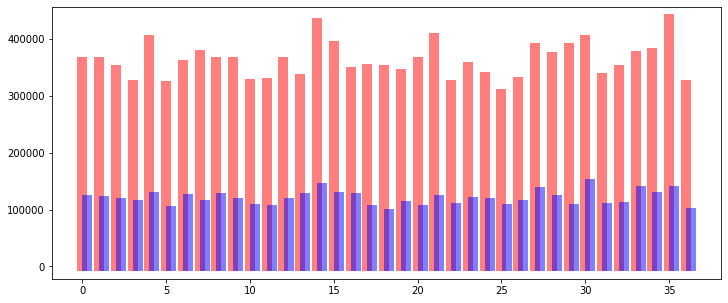

In [80]:
import glob
import os

n=0
files = glob.glob('../../STO/WWBr-IsolatedSounds/Flu_aif/*.aif')
for f in files:
    size = os.path.getsize(f)
#    print(f, size)
    stub = f.split('.')[-2]
    stub = stub.split('\\')[-1]
    stub = stub.split('-', maxsplit=2)[-2]
#    print('stub', stub)
#    note = df[df['Pitch']==stub]['Pitch'].values[0]
#    print('note', note)
    start = df[df['Pitch']==stub]['Start'].values[0]
#    print('start', start)
    end = df[df['Pitch']==stub]['End'].values[0]
    mid = end - start
#    print(start, end, mid, size)
    
    plt.plot([n,n],[0, size], 'r-', lw=10, alpha=0.5)
    plt.plot([n+0.3,n+0.3],[0, mid], 'b-', lw=10, alpha=0.5)
    print(mid/size)
    
    n+=1

In [90]:
len(sounddata)

159232

In [89]:
soundlen = len(sounddata)

In [82]:
end-begin

101720

In [85]:
begin/soundlen

0.16664363946945338

In [86]:
end/soundlen

0.8054599577974276

In [87]:
(end-begin)/4096

24.833984375

In [88]:
(end-begin)/soundlen

0.6388163183279743

In [91]:
size = os.path.getsize(insound)

In [92]:
size

318542

In [93]:
soundlen

159232

In [94]:
soundlen/size

0.49987756716539733

In [88]:
(end-begin)/soundlen

0.6388163183279743

0.6354612542414878


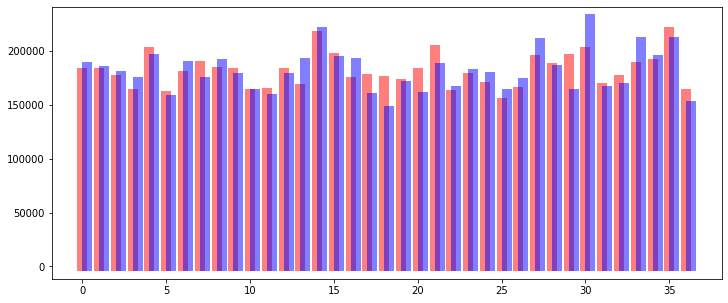

In [103]:
n=0
files = glob.glob('../../STO/WWBr-IsolatedSounds/Flu_aif/*.aif')

ratio = []

for f in files:
    size = os.path.getsize(f)
#    print(f, size)
    stub = f.split('.')[-2]
    stub = stub.split('\\')[-1]
    stub = stub.split('-', maxsplit=2)[-2]
#    print('stub', stub)
#    note = df[df['Pitch']==stub]['Pitch'].values[0]
#    print('note', note)
    start = df[df['Pitch']==stub]['Start'].values[0]
#    print('start', start)
    end = df[df['Pitch']==stub]['End'].values[0]
    mid = end - start
#    print(start, end, mid, size)
    
    plt.plot([n,n],[0, 0.5*size], 'r-', lw=10, alpha=0.5)
    plt.plot([n+0.3,n+0.3],[0, mid/0.6354612542414878], 'b-', lw=10, alpha=0.5)
#    print(mid/size)
    ratio.append(2*mid/size)
    n+=1
    
ratio = np.array(ratio)
ratio_mean = ratio.mean()
print(ratio_mean)

In [88]:
(end-begin)/soundlen

0.6388163183279743

---


# Looping over the sound files to make FFTs

In [104]:
pwd

'C:\\Users\\jhetrick\\Dropbox\\Research\\Music\\OrchestrationEngine\\Notebooks'

In [111]:
ls ..\Soundbank_McGill

 Volume in drive C is Windows
 Volume Serial Number is E249-8003

 Directory of C:\Users\jhetrick\Dropbox\Research\Music\OrchestrationEngine\Soundbank_McGill

04/24/2020  03:36 PM    <DIR>          .
04/24/2020  03:36 PM    <DIR>          ..
04/08/2020  10:34 AM    <DIR>          ForJim
04/13/2020  01:25 PM    <DIR>          ForJim-04-08-20
08/31/2019  09:42 PM        12,851,531 MUMS-Pno-Sax-Perc.pdf
08/31/2019  09:38 PM        15,372,055 MUMS-String.pdf
08/31/2019  09:37 PM        13,480,207 MUMS-WW-Br.pdf
08/04/2019  11:34 PM               172 NOTES.txt
04/12/2020  05:41 PM    <DIR>          Soundbank_PianoPercSax
04/24/2020  03:41 PM    <DIR>          Soundbank_Str
04/13/2020  01:27 PM    <DIR>          Soundbank_WB
               4 File(s)     41,703,965 bytes
               7 Dir(s)  56,213,852,160 bytes free


In [120]:
cd ../Soundbank_McGill/Soundbank_WB/

C:\Users\jhetrick\Dropbox\Research\Music\OrchestrationEngine\Soundbank_McGill\Soundbank_WB


In [121]:
ls

 Volume in drive C is Windows
 Volume Serial Number is E249-8003

 Directory of C:\Users\jhetrick\Dropbox\Research\Music\OrchestrationEngine\Soundbank_McGill\Soundbank_WB

04/13/2020  01:27 PM    <DIR>          .
04/13/2020  01:27 PM    <DIR>          ..
04/13/2020  01:26 PM            51,662 afl-a3-ord-mf.aif
04/13/2020  01:26 PM            56,677 afl-a4-ord-mf.aif
04/13/2020  01:26 PM            60,021 afl-a5-ord-mf.aif
04/13/2020  01:26 PM            33,271 afl-as3-ord-mf.aif
04/13/2020  01:26 PM            47,900 afl-as4-ord-mf.aif
04/13/2020  01:26 PM            60,021 afl-as5-ord-mf.aif
04/13/2020  01:26 PM            49,154 afl-b3-ord-mf.aif
04/13/2020  01:26 PM            51,662 afl-b4-ord-mf.aif
04/13/2020  01:26 PM            58,349 afl-b5-ord-mf.aif
04/13/2020  01:26 PM            43,302 afl-c4-ord-mf.aif
04/13/2020  01:26 PM            50,826 afl-c5-ord-mf.aif
04/13/2020  01:26 PM            57,095 afl-c6-ord-mf.aif
04/13/2020  01:26 PM            55,005 afl-cs4-ord-mf.aif

In [124]:
files = glob.glob('*.aif')
print(len(files))

639


In [123]:
for f in files[:3]:
    print(f)

afl-a3-ord-mf.aif
afl-a4-ord-mf.aif
afl-a5-ord-mf.aif


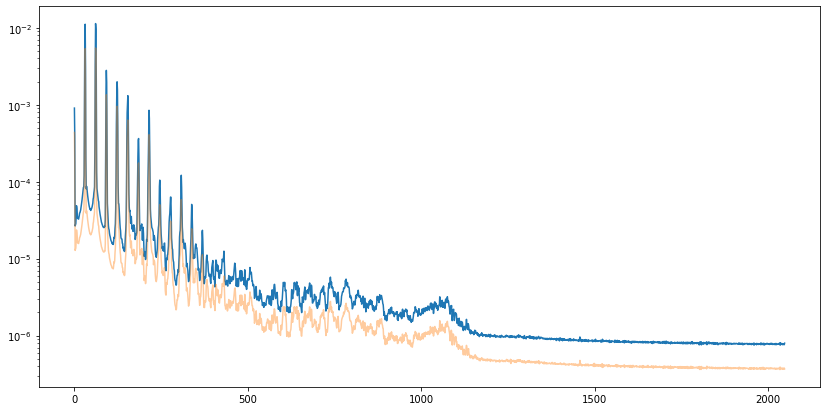

In [137]:
setPLTdisplay(14,7)

plt.plot(range(2048), nbbfft)
plt.plot(range(2048), xf_ave[:2048]/2e7, alpha=0.4)
plt.yscale('log')
#plt.xlim(0,500)

### Choose sound

In [138]:
pwd

'C:\\Users\\jhetrick\\Dropbox\\Research\\Music\\OrchestrationEngine\\Soundbank_McGill\\Soundbank_WB'

In [139]:
cd ../../Notebooks/

C:\Users\jhetrick\Dropbox\Research\Music\OrchestrationEngine\Notebooks


In [ ]:
instrument = 'flu-e4-ord-mf'
folder = 'Soundbank_WB'

print('../Soundbank_McGill/' + folder +'/'+ instrument + '.aif')

In [252]:
#infile = '../Soundbank_McGill/' + folder +'/'+ instrument + '.aif'
#infile = '../../STO/WWBr-IsolatedSounds/Flu_aif/flu-e4-ord-mf.aif'
#infile = '../../STO/WWBr-IsolatedSounds/Flu_aif/flu-e4-ord-mf.wav'
infile = '../Soundbank_McGill/' + folder +'/'+ instrument + '.aif'

In [263]:
sound = AudioSegment.from_file(infile)

sound = sound.set_channels(1)
sounddata = sound.get_array_of_samples()

### Select `begin` and `end` points

In [264]:
soundlen = len(sounddata)
soundlen

144825

In [265]:
2*soundlen

289650

In [282]:
shave_percent = 0.15

begin = np.int(shave_percent * soundlen)
end = np.int((1 - shave_percent) * soundlen)

In [284]:
print(soundlen)
print(begin)
print(end)

144825
28965
115860


**Set begin/end "by hand"**

In [285]:
#begin, end = 26535, 129800

### Do FFT

In [286]:
n = 0
xf_ave = np.zeros(2048)

for i in range(begin, end-4096, 512):
    x = sounddata[i:i+4096]
    x = x * hamwin
    xf = fft(x)
    xf_ave += (np.absolute(xf)**2)[:2048]
    
    n+=1
    
xf_ave = np.sqrt(xf_ave)/n
xf_ave

array([5.840e+08, 2.493e+08, 1.534e+07, ..., 4.061e+05, 4.061e+05,
       4.061e+05])

In [287]:
norm = xf_ave[0]/nbbfft[0]
norm

645677642499.2324

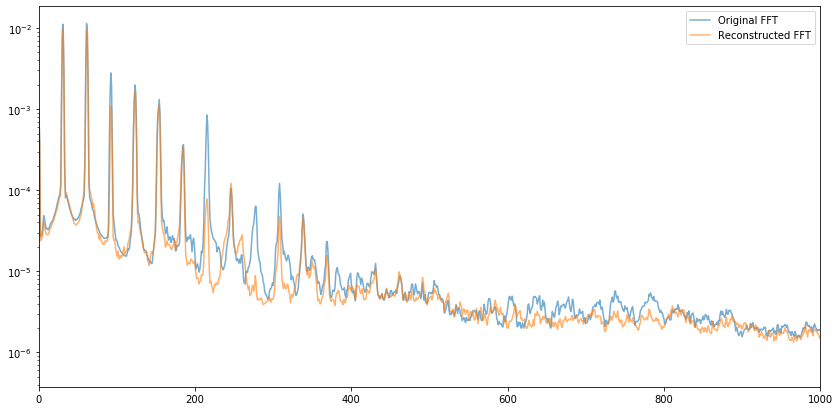

In [294]:
plt.plot(range(2048), nbbfft, label="Original FFT", alpha=0.6)
plt.plot(range(2048), xf_ave[:2048]/norm, alpha=0.6, label="Reconstructed FFT")
plt.yscale('log')
plt.xlim(0,1000)
plt.legend()

In [239]:
soundlen

289650

In [165]:
np.array(sounddata)

array([ -477218,   211180,  -506204, ..., -1611284, -3118898, -1158386],
      dtype=int32)

---

In [166]:
instrument = 'flu-e4-ord-mf'
folder = 'Soundbank_WB'

print('../Soundbank_McGill/' + folder +'/'+ instrument + '.aif')

sound = AudioSegment.from_file('../Soundbank_McGill/' + folder +'/'+ instrument + '.aif')
sounddata = sound.get_array_of_samples()

../Soundbank_McGill/Soundbank_WB/flu-e4-ord-mf.aif


In [167]:
sounddata

array('i', [-477218, 211180, -506204, 65248, -402002, -8085, -260662, -51717, -48364, -204364, 150848, -478594, 173624, -776304, -20746, -970958, -353767, -990361, -693970, -860505, -1004121, -721400, -1384946, -715715, -1856734, -748939, -2333674, -629394, -2753360, -462204, -3005224, -437689, -2999726, -424012, -2850028, -300532, -2692477, -300825, -2487909, -600637, -2131226, -1025871, -1586515, -1403350, -944969, -1782312, -332386, -2203654, 230296, -2590750, 658794, -2941065, 765489, -3333723, 646597, -3677044, 599678, -3764068, 590796, -3621762, 363586, -3447104, -97369, -3253969, -616971, -2961516, -1107502, -2635314, -1584600, -2292532, -1972666, -1810879, -2088345, -1287601, -2003795, -1024410, -2045062, -1022306, -2186320, -1005414, -2111686, -924724, -1893770, -948356, -1779618, -1100188, -1664984, -1322728, -1501035, -1694173, -1541164, -2242288, -1754808, -2727387, -1775758, -2927529, -1574632, -2965170, -1528321, -3003301, -1800328, -2907800, -2125172, -2625656, -2284594,

In [198]:

oldsound = AudioSegment.from_file('../../STO/WWBr-IsolatedSounds/Flu_aif/flu-e4-ord-mf.wav')
oldsounddata = sound.get_array_of_samples()

In [199]:
oldsounddata

array('h', [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0

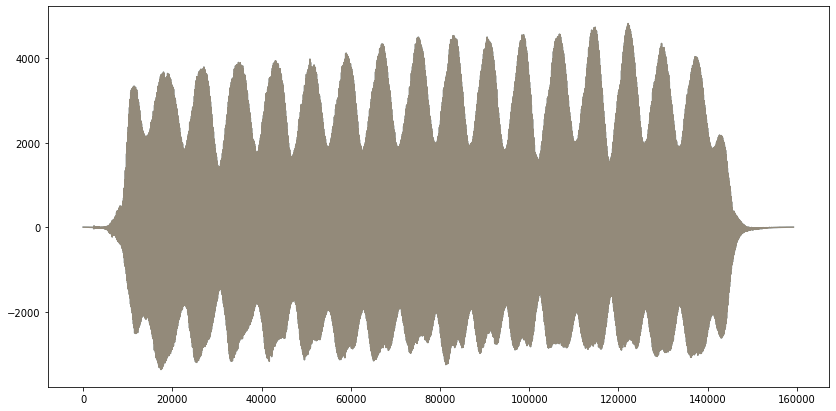

In [200]:
plt.plot(range(len(sounddata)), sounddata, alpha=0.8)
plt.plot(range(len(oldsounddata)), oldsounddata, alpha=0.4)

#plt.plot([begin,begin], [-3000,3000],'r')
#plt.plot([end,end], [-3000,3000],'r')

---


# Start over

In [ ]:
#!pip install pydub

### Setup for pipeline

In [1]:
from pydub import AudioSegment
from pydub.playback import play
from scipy.fftpack import fft, ifft

import glob
import os
from os import path
import random

#### Shave off attack/decay and make Hamming window

In [2]:
shave_percent = 0.15
hamwin = np.hamming(4096)

## Compare with previous

Make a dictionary of matching FFT and AIF files

In [79]:
nbbfiles = glob.glob('../FFTBank/*.nbb')
sndfiles = glob.glob('../Soundbank_McGill/' + folder + '/*.aif')

#for f in files[316:317]: ### flu-e4-ord-mf
#rnbb = np.random.choice(nbbfiles, size=3, replace=False)
#print(rnbb)

nbb_snd = {}
for fnbb in nbbfiles:    
    f = (fnbb.split('\\')[1])
    f = f.split('.')[0]
    
    for d in ['Soundbank_WB', 'Soundbank_Str', 'Soundbank_PianoPercSax']:
        if(path.exists('../SoundBank_McGill/' + d + '/' + f + '.aif')):
            fsnd = '../SoundBank_McGill/' + d + '/' + f + '.aif'
            #print(fnbb, f)
            nbb_snd[f] = fsnd


5 2
['vla-c5-ord-mf' 'bsn-e2-ord-mf' 'bsn-as1-ord-mf' 'trb-f4-stm-mf'
 'vln-fs5-ord-mf' 'bsn-c3-ord-mf' 'trb-as3-ord-mf' 'obo-fs4-ord-mf'
 'vln-fs4-ord-mf' 'vla-as3-ord-mf']
0 vla-c5-ord-mf
1 bsn-e2-ord-mf
2 bsn-as1-ord-mf
3 trb-f4-stm-mf
4 vln-fs5-ord-mf
5 bsn-c3-ord-mf
6 trb-as3-ord-mf
7 obo-fs4-ord-mf
8 vln-fs4-ord-mf
9 vla-as3-ord-mf


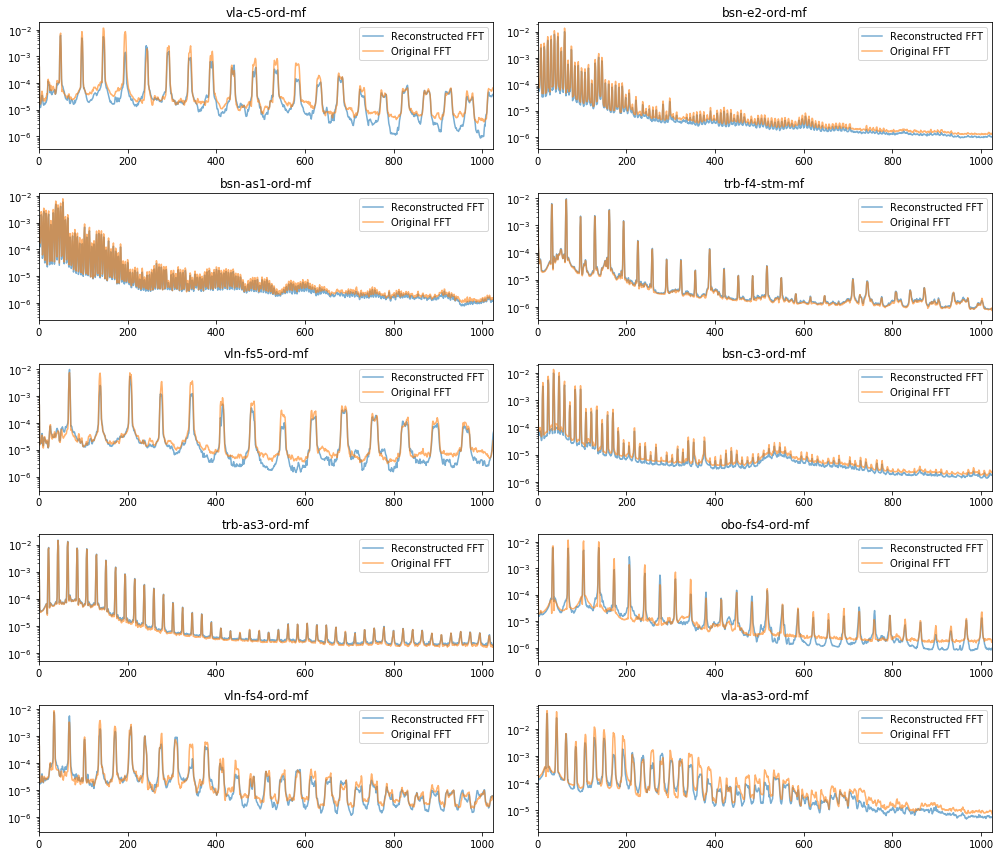

In [98]:
# set the random seed for reproducibility
np.random.seed(749)

# plot grid dimensions
nbym = (5,2)

plt.figure(figsize=(14,12))

print(nbym[0], nbym[1])
rnbb = np.random.choice(list(nbb_snd.keys()), size=nbym[0]*nbym[1], replace=False)

print(rnbb)
for k,s in enumerate(rnbb):
    print(k,s)
            
    nbbfft = np.fromfile('../FFTBank/' + s + '.nbb', dtype='float32')
    sound = AudioSegment.from_file(nbb_snd[s])
    sound = sound.set_channels(1)
    sounddata = sound.get_array_of_samples()
    soundlen = len(sounddata)
    begin = np.int(shave_percent * soundlen)
    end = np.int((1 - shave_percent) * soundlen)
    
    n = 0
    xf_ave = np.zeros(2048)

    
    # Average over blocks of size 4096 
    for i in range(begin, end-4096, 512):
        x = sounddata[i:i+4096]
        x = x * hamwin
        xf = fft(x)
        xf_ave += (np.absolute(xf)**2)[:2048]
#        xf_ave += (xf**2)[:2048]
        n+=1
    
    xf_ave = np.sqrt(xf_ave)/n    

    # normalize
    xf_ave /= xf_ave.sum()
    norm = xf_ave[0]/nbbfft[0]
#    print('xf', xf_ave[0], 'nbb', nbbfft[0], norm)
    
    plt.subplot(nbym[0], nbym[1], k+1)
    plt.plot(range(2048), xf_ave[:2048]/norm, alpha=0.6, label="Reconstructed FFT")
    plt.plot(range(2048), nbbfft , alpha=0.6, label="Original FFT")
    plt.yscale('log')
    #plt.xlim(0,2048)
    plt.xlim(0,1024)
    plt.title(s)
    plt.legend()
    plt.tight_layout()

---

## Create FFT files in 3 subdirs: FFTBank_ +  [WB, Str, PianoPercSax]

In [105]:

#folder = 'WB'
#folder = 'Str'
folder = 'PianoPercSax'


files = glob.glob('../Soundbank_McGill/soundbank_' + folder + '/*.aif')

for f in files:
#    print(f)

    sound = AudioSegment.from_file(f)
    sound = sound.set_channels(1)
    sounddata = sound.get_array_of_samples()
    soundlen = len(sounddata)
    begin = np.int(shave_percent * soundlen)
    end = np.int((1 - shave_percent) * soundlen)
    
    # Average over blocks of size 4096 
    n = 0
    xf_ave = np.zeros(2048)   
    for i in range(begin, end-4096, 512):
        x = sounddata[i:i+4096]
        x = x * hamwin
        xf = fft(x)
        xf_ave += (np.absolute(xf)**2)[:2048]
        n+=1
    
    xf_ave = np.sqrt(xf_ave)/n    

    # Normalize
    xf_ave /= xf_ave.sum()
        
#    plt.plot(range(2048), xf_ave[:2048], alpha=0.6, label="Reconstructed FFT")
#    plt.plot(range(2048),  , alpha=0.6, label="Original FFT")
#    plt.yscale('log')
    #plt.xlim(0,2048)
#    plt.xlim(0,1024)
#    plt.legend()

# Save to file as text
    stub = (f.split('\\')[1])
    stub = stub.split('.')[0]
    fftfile = '../Soundbank_McGill/FFTBank_' + folder + '/' + stub + '.txt'
    print(fftfile)
    np.savetxt(fftfile, xf_ave)
    

../Soundbank_McGill/FFTBank_PianoPercSax/alx-a4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-as4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-b4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-c5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-cs4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-cs5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-d4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-d5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-ds4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-e4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-f4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-fs4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-g4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/alx-gs4-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/brx-a2-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/brx-as2-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/brx-b2-o

../Soundbank_McGill/FFTBank_PianoPercSax/pno-b0-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b1-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b1-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b2-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b2-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b3-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b3-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b4-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b4-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b5-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b5-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b6-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b6-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b7-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-b7-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-c1-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-c1-ord-pp.t

../Soundbank_McGill/FFTBank_PianoPercSax/pno-gs5-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-gs6-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-gs6-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-gs7-ord-ff.txt
../Soundbank_McGill/FFTBank_PianoPercSax/pno-gs7-ord-pp.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-a5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-as5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-b5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-c6-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-cs5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-cs6-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-d5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-d6-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-ds5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-ds6-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-e5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/spx-f

../Soundbank_McGill/FFTBank_PianoPercSax/xyl-b6-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-b7-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-c5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-c6-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-c7-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-c8-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-cs5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-cs6-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-cs7-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-d5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-d6-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-d7-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-ds5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-ds6-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-ds7-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-e5-ord-mf.txt
../Soundbank_McGill/FFTBank_PianoPercSax/xyl-e6-or